# 第 7 章 仿真随机服务系统 —— 代码实现

对应笔记 `docs/mc/ch07.md`。四个实验：泊松过程的到达与间隔、M/M/1 事件调度模拟器与理论验证、瞬态识别与 burn-in、三种系统对比（变异性如何拉长等待）。

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch07")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2030)

## 7.1 泊松过程：到达计数与指数间隔

指数间隔累加即泊松过程（ch4 乘积法的“正名”）：计数阶梯 vs 直线 λt；间隔直方图 vs Exp(1)。

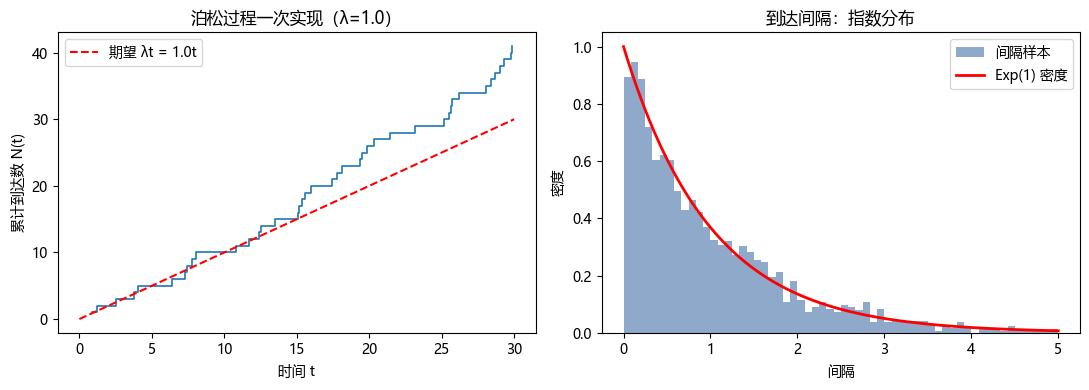

In [7]:
lam, T = 1.0, 30.0
gaps = rng.exponential(1/lam, 3000)
arr = np.cumsum(gaps)
arr = arr[arr < T]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].step(arr, np.arange(1, len(arr) + 1), where="post", lw=1.2)
axes[0].plot([0, T], [0, lam * T], "r--", lw=1.5, label=f"期望 λt = {lam}t")
axes[0].set(title=f"泊松过程一次实现（λ={lam}）", xlabel="时间 t", ylabel="累计到达数 N(t)")
axes[0].legend()
axes[1].hist(gaps[:2000], bins=60, range=(0, 5), density=True, color="#8ea9c9", label="间隔样本")
xx = np.linspace(0, 5, 300)
axes[1].plot(xx, np.exp(-xx), "r-", lw=2, label="Exp(1) 密度")
axes[1].set(title="到达间隔：指数分布", xlabel="间隔", ylabel="密度"); axes[1].legend()
fig.tight_layout(); save(fig, "out-poisson-process.png"); plt.show()

## 7.2 M/M/1 事件调度模拟器

λ=0.8、μ=1（ρ=0.8）。理论：Wq=ρ/(μ−λ)=4，W=5，L=λW=4。20 个独立 replica（每个 T=20000）。

In [8]:
def mm1(lam, mu, T, rng):
    t = next_arr = rng.exponential(1/lam)
    next_dep = np.inf
    in_service = None                     # 正在服务的顾客的“到达时刻”（算 W 要用）
    queue = deque()
    Wq, W = [], []
    while t < T:
        if next_arr < next_dep:           # —— 到达事件
            t = next_arr
            if in_service is None:
                in_service = t; Wq.append(0.0)
                next_dep = t + rng.exponential(1/mu)
            else:
                queue.append(t)
            next_arr = t + rng.exponential(1/lam)
        else:                             # —— 离开事件
            t = next_dep
            W.append(t - in_service)      # 逗留 = 离开 − 到达
            if queue:
                in_service = queue.popleft()
                Wq.append(t - in_service) # 排队等待 = 开始服务 − 到达
                next_dep = t + rng.exponential(1/mu)
            else:
                in_service = None; next_dep = np.inf
    return np.array(Wq), np.array(W)

lam, mu = 0.8, 1.0
reps = 20
Wq_r = np.array([mm1(lam, mu, 20000, rng)[0][500:].mean() for _ in range(reps)])
W_r  = np.array([mm1(lam, mu, 20000, rng)[1][500:].mean() for _ in range(reps)])

print(f"Wq: 模拟 {Wq_r.mean():.3f} ± {Wq_r.std():.3f}（理论 {lam/(mu-lam):.2f}）")
print(f"W : 模拟 {W_r.mean():.3f} ± {W_r.std():.3f}（理论 {1/(mu-lam):.2f}）")
print(f"L : 模拟 {lam*W_r.mean():.3f}（理论 λW = {lam/(mu-lam):.2f}）← Little 定律")

Wq: 模拟 3.995 ± 0.280（理论 4.00）
W : 模拟 4.982 ± 0.293（理论 5.00）
L : 模拟 3.986（理论 λW = 4.00）← Little 定律


## 7.3 瞬态与 burn-in

一条长实现的 Wq 滑动均值：从 0 爬升到稳态 4 的过程——前段样本必须丢弃。

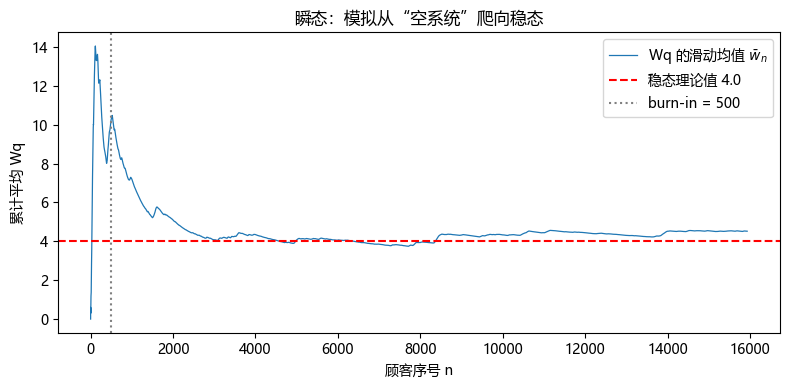

前 100 人均值 13.25，全样本均值 4.52


In [9]:
Wq_all = mm1(lam, mu, 20000, rng)[0]
run = np.cumsum(Wq_all) / np.arange(1, len(Wq_all) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(run, lw=0.9, label=r"Wq 的滑动均值 $\bar w_n$")
ax.axhline(4.0, color="r", ls="--", lw=1.5, label="稳态理论值 4.0")
ax.axvline(500, color="gray", ls=":", lw=1.5, label="burn-in = 500")
ax.set(xlabel="顾客序号 n", ylabel="累计平均 Wq", title="瞬态：模拟从“空系统”爬向稳态")
ax.legend(); fig.tight_layout(); save(fig, "out-transient.png"); plt.show()
print(f"前 100 人均值 {Wq_all[:100].mean():.2f}，全样本均值 {Wq_all.mean():.2f}")

## 7.4 变异性是敌人：三种系统同场竞技

同 λ=0.8、同总服务能力：M/M/1（μ=1）vs M/M/2（2 台×μ=0.5）vs M/G/1（Erlang-3 服务，均值 1、波动更小）。理论 Wq：4.00 / 3.56 / 2.67。

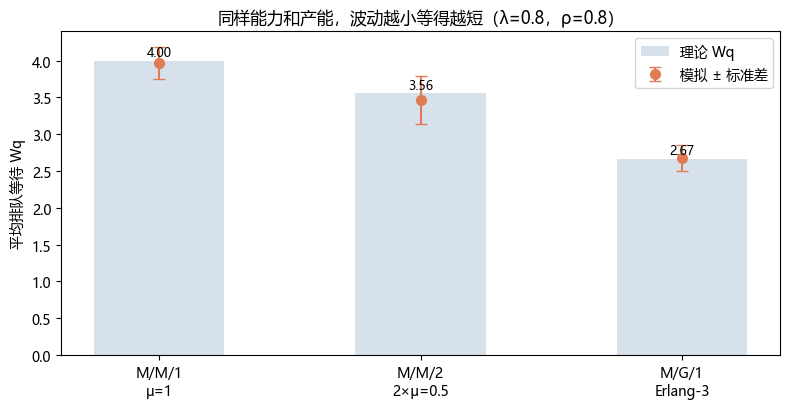

模拟均值: [3.969 3.465 2.676] 理论: [4.0, 3.556, 2.667]


In [10]:
def mg1_erlang(lam, mu_phase, k, T, rng):
    t = next_arr = rng.exponential(1/lam)
    next_dep = np.inf; in_service = None; queue = deque()
    Wq = []
    while t < T:
        if next_arr < next_dep:
            t = next_arr
            if in_service is None:
                in_service = t; Wq.append(0.0)
                next_dep = t + rng.exponential(1/mu_phase, k).sum()
            else:
                queue.append(t)
            next_arr = t + rng.exponential(1/lam)
        else:
            t = next_dep
            if queue:
                in_service = queue.popleft()
                Wq.append(t - in_service)
                next_dep = t + rng.exponential(1/mu_phase, k).sum()
            else:
                in_service = None; next_dep = np.inf
    return np.array(Wq)

def mmc2(lam, mu, T, rng):
    t = next_arr = rng.exponential(1/lam)
    deps = [np.inf, np.inf]; busy = [None, None]   # busy[i] = 台 i 正服务顾客的到达时刻
    queue = deque(); Wq = []
    while t < T:
        i_dep = int(np.argmin(deps))
        if next_arr < deps[i_dep]:
            t = next_arr
            free = 0 if busy[0] is None else (1 if busy[1] is None else None)
            if free is not None:
                busy[free] = t; Wq.append(0.0)
                deps[free] = t + rng.exponential(1/mu)
            else:
                queue.append(t)
            next_arr = t + rng.exponential(1/lam)
        else:
            t = deps[i_dep]
            if queue:
                busy[i_dep] = queue.popleft()
                Wq.append(t - busy[i_dep])
                deps[i_dep] = t + rng.exponential(1/mu)
            else:
                busy[i_dep] = None; deps[i_dep] = np.inf
    return np.array(Wq)

wq_mm1 = np.array([mm1(lam, 1.0, 20000, rng)[0][500:].mean() for _ in range(15)])
wq_mm2 = np.array([mmc2(lam, 0.5, 20000, rng)[500:].mean() for _ in range(15)])
wq_mg1 = np.array([mg1_erlang(lam, 3.0, 3, 20000, rng)[500:].mean() for _ in range(15)])

names = ["M/M/1\nμ=1", "M/M/2\n2×μ=0.5", "M/G/1\nErlang-3"]
theory = [4.0, 3.556, 2.667]
sims = [wq_mm1.mean(), wq_mm2.mean(), wq_mg1.mean()]
errs = [wq_mm1.std(), wq_mm2.std(), wq_mg1.std()]

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(names, theory, width=0.5, alpha=0.35, color="#8ea9c9", label="理论 Wq")
ax.errorbar(names, sims, yerr=errs, fmt="o", ms=7, color="#e07b54", capsize=4, label="模拟 ± 标准差")
for b, v in zip(bars, theory):
    ax.text(b.get_x() + b.get_width()/2, v + 0.06, f"{v:.2f}", ha="center", fontsize=9)
ax.set(ylabel="平均排队等待 Wq", title="同样能力和产能，波动越小等得越短（λ=0.8，ρ=0.8）")
ax.legend(); fig.tight_layout(); save(fig, "out-compare.png"); plt.show()
print("模拟均值:", np.round(sims, 3), "理论:", theory)